In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

flights = pd.read_csv("data/raw/flights.csv")
weather = pd.read_csv("data/raw/weather.csv")
airlines = pd.read_csv("data/raw/airlines.csv")
analysis = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

In [9]:
analysis["scheduled_time_bucket"] = pd.cut(
    analysis["scheduled_hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Overnight", "Morning", "Afternoon", "Evening"],
)

print(analysis["scheduled_time_bucket"].value_counts(dropna=False))


scheduled_time_bucket
Afternoon    127017
Morning      126646
Evening       71743
Overnight      1940
Name: count, dtype: int64


In [20]:
time_stats = (
    analysis.groupby("scheduled_time_bucket").agg(
        Flights = ("arr_delay", "count"),
        Avg_Delay = ("arr_delay", "mean"),
        Median_Delay = ("arr_delay", "median"),
        Std_Delay = ("arr_delay", "std"),
        Min_Delay = ("arr_delay", "min"),
        Max_Delay = ("arr_delay", "max"), 
        Delay_over_15_Pct = ("arr_delay", lambda x: (x > 15).mean() * 100),
        Delay_over_30_Pct = ("arr_delay", lambda x: (x > 30).mean() * 100),
        
    ).reset_index()
)
print(time_stats)

  scheduled_time_bucket  Flights  Avg_Delay  Median_Delay  Std_Delay  \
0             Overnight     1940  -4.796907          -8.0  22.238266   
1               Morning   126646  -1.777916          -8.0  33.202622   
2             Afternoon   127017  10.427029          -3.0  48.198320   
3               Evening    71743  16.269685           0.0  52.639441   

   Min_Delay  Max_Delay  Delay_over_15_Pct  Delay_over_30_Pct  
0      -51.0      208.0           9.948454           4.536082  
1      -79.0     1272.0          14.681080           8.174755  
2      -86.0     1109.0          27.087713          18.269208  
3      -75.0     1127.0          34.063254          24.884658  


In [14]:
print("Total flights:", time_stats["Flights"].sum())

display (time_stats[["scheduled_time_bucket", "Flights"]])

Total flights: 327346


,scheduled_time_bucket,Flights
0,Overnight,1940
1,Morning,126646
2,Afternoon,127017
3,Evening,71743


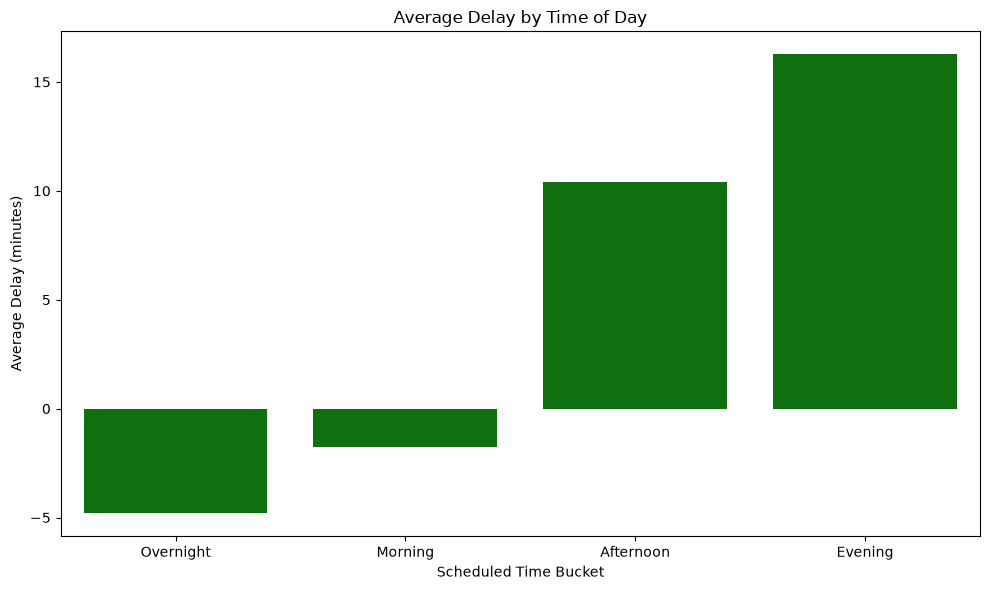

In [15]:
plot_data = time_stats.copy()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=plot_data,
    x="scheduled_time_bucket",
    y="Avg_Delay",
    color="green",
    ax=ax,
)
ax.set(
    title="Average Delay by Time of Day",
    xlabel="Scheduled Time Bucket",
    ylabel="Average Delay (minutes)",
)

plt.tight_layout()
plt.show()

In [22]:
plot_data = time_stats.melt(
    id_vars="scheduled_time_bucket",
    value_vars=["Delay_over_15_Pct", "Delay_over_30_Pct"],
    var_name="Delay_Threshold",
    value_name="Percentage",
)

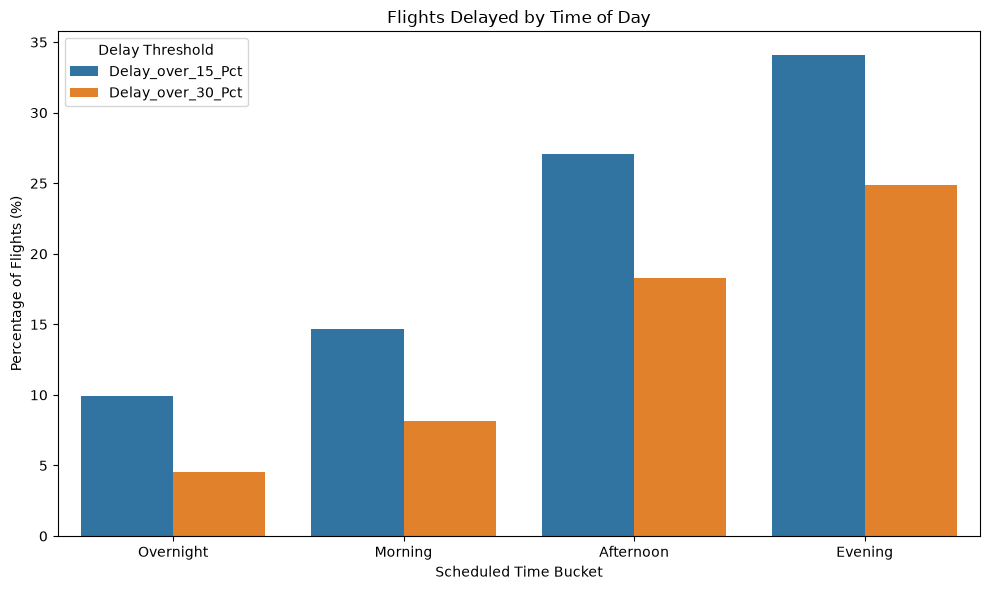

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="scheduled_time_bucket",
    y="Percentage",
    hue="Delay_Threshold",
    ax=ax,
)
ax.set(
    title="Flights Delayed by Time of Day",
    xlabel="Scheduled Time Bucket",
    ylabel="Percentage of Flights (%)",
)

plt.legend(title = "Delay Threshold")
plt.tight_layout()
plt.show()

In [24]:
highest = time_stats.loc[time_stats["Delay_over_15_Pct"].idxmax()]
lowest = time_stats.loc[time_stats["Delay_over_15_Pct"].idxmin()]
print(
    f"Highest average delay: {highest['scheduled_time_bucket']}"
    f" ({highest['Avg_Delay']} minutes)"
)
print(
    f"Lowest average delay: {lowest['scheduled_time_bucket']}"
    f" ({lowest['Avg_Delay']} minutes)"
)

Highest average delay: Evening (16.269684847302177 minutes)
Lowest average delay: Overnight (-4.796907216494845 minutes)
